# 02. EDA(탐색적 데이터 분석) & 시각화

> **배우는 것**: seaborn `countplot` · `histplot` · `kdeplot` · `boxplot` · `scatterplot` · `jointplot` · `barplot` · `heatmap` + matplotlib 제목/축/범례 + **그래프 해석**
> ⏱ 예상 소요시간: 50분  |  📑 같이 볼 슬라이드: `slides/02_EDA_시각화.html`

**EDA 는 "데이터와 대화하기"** 예요. 그래프를 그리는 목적은 예쁜 그림이 아니라 **질문에 답하기**입니다.
- 이탈 고객이 얼마나 되지? → `countplot`
- 가입기간 분포는? → `histplot` / `kdeplot`
- 튀는 값(이상치)이 있나? → `boxplot` / `jointplot`
- 무엇이 이탈과 관련 있지? → `barplot` / `heatmap`

> 📝 **시험 포인트**: 시각화 문항은 보통 "seaborn 으로 ○○ 그래프를 그리고, **이상치를 찾아 제거**하라" 처럼 다음 전처리 문항과 이어져요.
> 축 이름은 **영어**로 쓰세요 (시험 환경에 한글 폰트가 없으면 글자가 □□□ 로 깨져요).

In [1]:
# ▶ 맨 처음 한 번 실행하세요 (정답 노트북: 한 단계 위 폴더 기준)
import warnings
warnings.filterwarnings('ignore')

import sys
sys.path.insert(0, '..')       # 정답 폴더에서 aice_check 찾기
DATA_DIR = '../../data/'
import aice_check as check

### ✏️ 문제 1. import
matplotlib 의 pyplot 을 **`plt`**, seaborn 을 **`sns`** 로 불러오세요.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<details><summary>💡 힌트 (막히면 클릭)</summary>

`import matplotlib.pyplot as plt` — pyplot 까지 써야 해요!

</details>

In [3]:
check.p02_q1()

✅ [P02 문제 1] matplotlib / seaborn import — 정답!


데이터를 읽고, 01 에서 배운 대로 `TotalCharges` 를 숫자로, `Churn` 을 0/1 로 바꿔 둡니다. (그냥 실행)

In [4]:
df = pd.read_csv(DATA_DIR + 'telco_churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['Churn_num'] = df['Churn'].map({'Yes': 1, 'No': 0})
df.shape

(3000, 19)

## 1. 범주형 데이터 → 개수 세기 `countplot`
**사용법**: `sns.countplot(data=df, x='컬럼')` — 막대 높이 = 그 값이 몇 번 나왔는지.
`hue='다른 컬럼'` 을 주면 색깔로 나눠서 보여줘요.

> 모든 seaborn 함수는 그린 그래프(**Axes**)를 돌려줘요. `ax2 = sns.countplot(...)` 처럼 받아두면 채점 도구가 확인할 수 있어요.

### ✏️ 문제 2. countplot
`Churn` 의 개수를 countplot 으로 그리고 **`ax2`** 에 저장하세요.

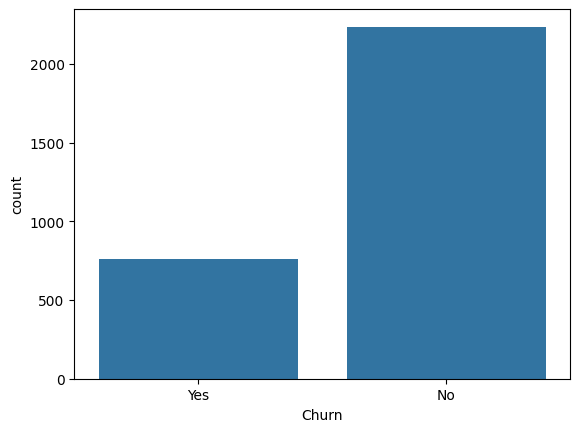

In [5]:
ax2 = sns.countplot(data=df, x='Churn')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`sns.countplot(data=df, x='Churn')`

</details>

In [6]:
check.p02_q2()

✅ [P02 문제 2] countplot — 정답!


### ✏️ 문제 3. countplot + hue
계약 형태 `Contract` 별 개수를, `Churn` 으로 색을 나눠 그리고 **`ax3`** 에 저장하세요.

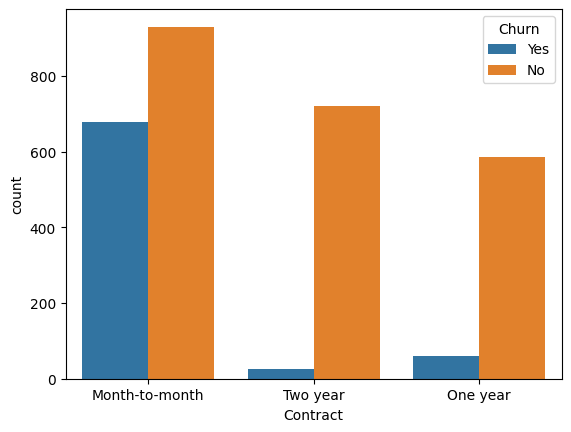

In [7]:
ax3 = sns.countplot(data=df, x='Contract', hue='Churn')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`hue='Churn'` — 무엇이 눈에 띄나요? 월 단위 계약에서 Yes 가 유난히 많죠.

</details>

In [8]:
check.p02_q3()

✅ [P02 문제 3] countplot + hue — 정답!


## 2. 숫자 데이터 → 분포 보기 `histplot` / `kdeplot`
- `histplot` : 구간(bin)을 나눠서 막대로 → 분포 모양
- `kdeplot` : 히스토그램을 부드러운 곡선으로 → `hue` 로 그룹 비교할 때 겹쳐도 잘 보여요

### ✏️ 문제 4. histplot
`tenure` 의 히스토그램을 **구간 30개**로 그리고 **`ax4`** 에 저장하세요.

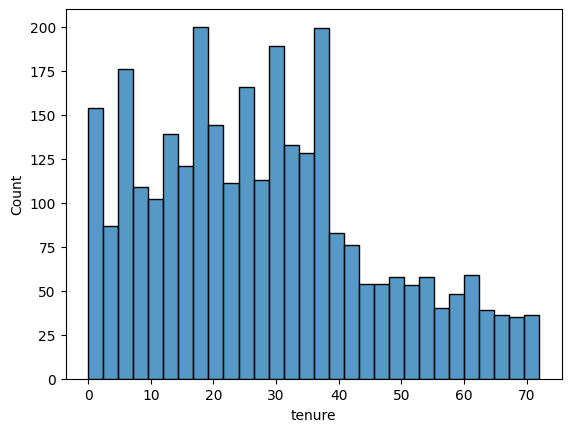

In [9]:
ax4 = sns.histplot(data=df, x='tenure', bins=30)
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`bins=30`

</details>

In [10]:
check.p02_q4()

✅ [P02 문제 4] histplot — 정답!


### ✏️ 문제 5. kdeplot + hue
`tenure` 분포를 `Churn` 별 곡선으로 그리고 **`ax5`** 에 저장하세요.

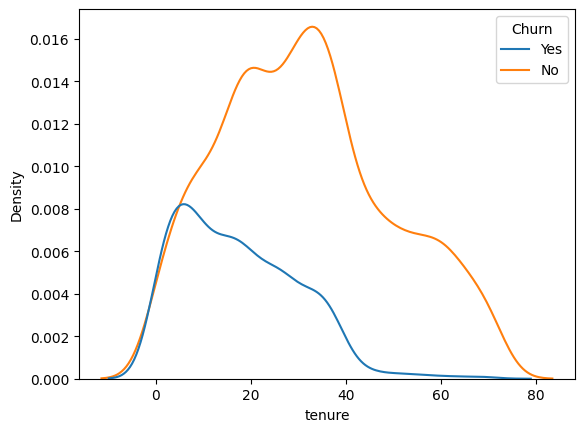

In [11]:
ax5 = sns.kdeplot(data=df, x='tenure', hue='Churn')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

해석: 이탈 고객(Yes) 곡선이 왼쪽(가입 초기)에 몰려 있어요 → **신규 고객이 잘 떠난다**

</details>

In [12]:
check.p02_q5()

✅ [P02 문제 5] kdeplot + hue — 정답!


## 3. 이상치(outlier) 찾기 `boxplot`
상자 = 가운데 50% 데이터, 가운데 선 = 중앙값, 수염 밖의 점 = **이상치 후보**
(수염 끝 = Q1 − 1.5×IQR, Q3 + 1.5×IQR → 03 전처리에서 계산해 봐요)

### ✏️ 문제 6. boxplot
`MonthlyCharges` 의 boxplot 을 **세로(y)** 로 그리고 **`ax6`** 에 저장하세요.

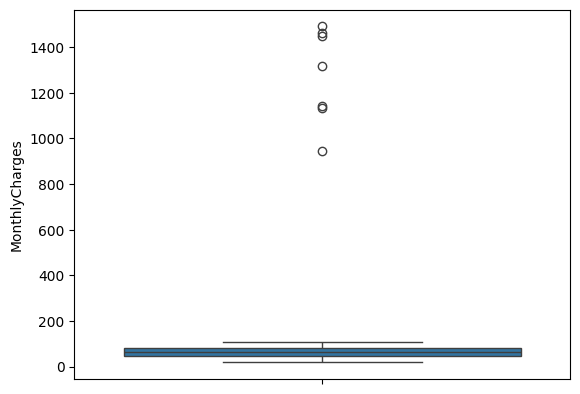

In [13]:
ax6 = sns.boxplot(data=df, y='MonthlyCharges')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`sns.boxplot(data=df, y='MonthlyCharges')` — 위쪽에 혼자 떨어진 점들이 보이죠?

</details>

In [14]:
check.p02_q6()

✅ [P02 문제 6] boxplot — 정답!


### ✏️ 문제 7. 이상치 개수 세기
월 요금이 **200 보다 큰** 행의 개수를 **`n_outliers`** 에 저장하세요. (월 요금 최대가 보통 120 정도라 900 이상은 입력 오류예요)

In [15]:
n_outliers = (df['MonthlyCharges'] > 200).sum()
n_outliers

7

<details><summary>💡 힌트 (막히면 클릭)</summary>

조건식은 True/False 를 만들고, `.sum()` 은 True 개수를 세요.

</details>

In [16]:
check.p02_q7()

✅ [P02 문제 7] 이상치 개수 세기 — 정답!
   이 7개는 입력 오류로 보여요 → 전처리에서 제거!


이상치를 뺀 데이터 `df_clean` 으로 이어서 그려볼게요. (그냥 실행)

In [17]:
df_clean = df[df['MonthlyCharges'] < 200]
len(df), len(df_clean)

(3000, 2993)

## 4. 두 숫자의 관계 `scatterplot` / `jointplot`
- `scatterplot` : 점 하나 = 고객 한 명
- `jointplot` : 산점도 + 위/오른쪽에 각 변수의 분포까지 → **공식 샘플 5번 문항**이 이거예요

### ✏️ 문제 8. scatterplot
x=`tenure`, y=`TotalCharges`, 색은 `Churn` 으로 산점도를 그리고 **`ax8`** 에 저장하세요. (데이터: `df_clean`)

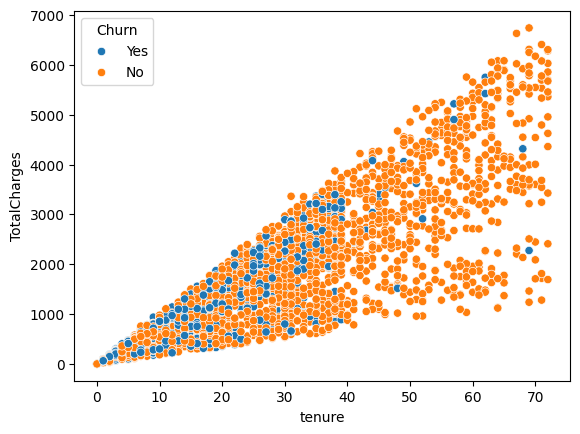

In [18]:
ax8 = sns.scatterplot(data=df_clean, x='tenure', y='TotalCharges', hue='Churn')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

가입기간이 길수록 누적요금도 커지는 우상향 관계가 보여요.

</details>

In [19]:
check.p02_q8()

✅ [P02 문제 8] scatterplot — 정답!


### ✏️ 문제 9. jointplot
x=`tenure`, y=`MonthlyCharges` 로 jointplot 을 그리고 **`g9`** 에 저장하세요. (데이터: `df_clean`)

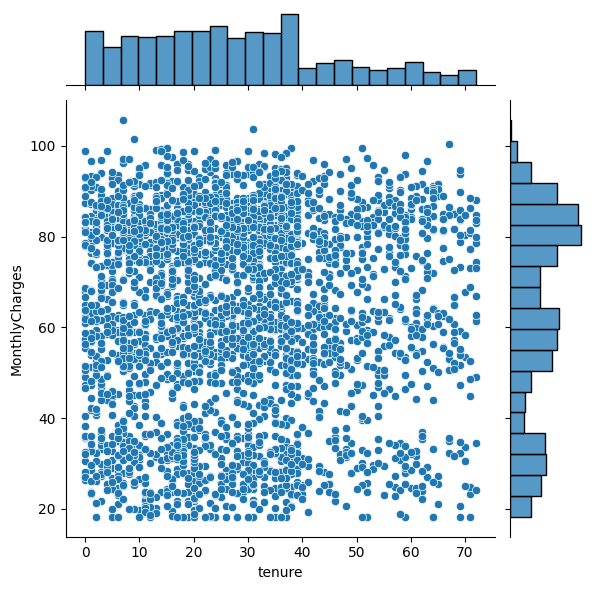

In [20]:
g9 = sns.jointplot(data=df_clean, x='tenure', y='MonthlyCharges')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

jointplot 은 그림 여러 개를 묶은 **JointGrid** 를 돌려줘요 (Axes 아님).

</details>

In [21]:
check.p02_q9()

✅ [P02 문제 9] jointplot — 정답!


## 5. 그룹별 평균 비교 `barplot` → 그래프 해석
`sns.barplot(data=df, x='그룹', y='숫자')` 의 막대 높이는 **그룹별 평균**이에요.
`y` 에 0/1 컬럼(`Churn_num`)을 넣으면 평균 = **이탈률**이 됩니다. (검은 선 = 신뢰구간)

### ✏️ 문제 10. barplot
x=`Contract`, y=`Churn_num` 으로 계약 형태별 이탈률 막대그래프를 그리고 **`ax10`** 에 저장하세요. (데이터: `df_clean`)

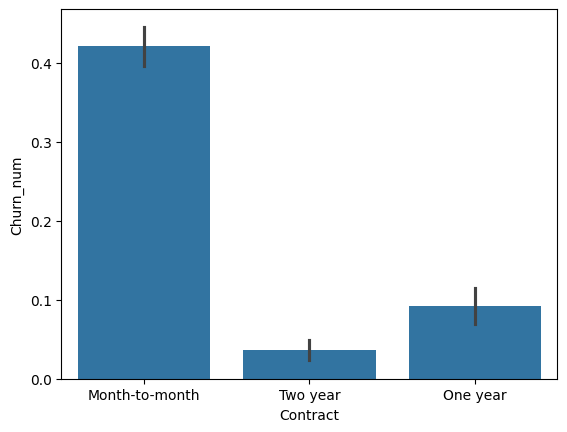

In [22]:
ax10 = sns.barplot(data=df_clean, x='Contract', y='Churn_num')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`sns.barplot(data=..., x=..., y=...)`

</details>

In [23]:
check.p02_q10()

✅ [P02 문제 10] barplot (평균 막대) — 정답!
   막대 높이 = 그룹별 평균 = 이탈률


### ✏️ 문제 11. 그래프 해석
위 그래프에서 **이탈률이 가장 높은 계약 형태**의 이름을 문자열로 **`answer11`** 에 저장하세요.
(`'Month-to-month'`, `'One year'`, `'Two year'` 중 하나)

In [24]:
answer11 = 'Month-to-month'

<details><summary>💡 힌트 (막히면 클릭)</summary>

막대가 가장 높은 것! 코드로 확인하려면 `df_clean.groupby('Contract')['Churn_num'].mean()`

</details>

In [25]:
check.p02_q11()

✅ [P02 문제 11] 그래프 해석: 이탈률이 가장 높은 계약 — 정답!
   월 단위 계약 고객이 가장 많이 떠나요.


## 6. 상관관계 `corr` + `heatmap`
상관계수: **−1 ~ 1**. 1 에 가까우면 같이 커지고, −1 에 가까우면 반대로 움직이고, 0 이면 관계 없음.

> ⚠️ `df.corr()` 은 숫자 컬럼만 계산할 수 있어요. 문자열 컬럼이 섞여 있으면 에러 → 숫자 컬럼만 골라서 쓰거나 `df.corr(numeric_only=True)`

### ✏️ 문제 12. corr
`tenure`, `MonthlyCharges`, `TotalCharges`, `Churn_num` 4개 컬럼의 상관계수 표를 **`corr`** 에 저장하세요.

In [26]:
corr = df_clean[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_num']].corr()
corr

,tenure,MonthlyCharges,TotalCharges,Churn_num
tenure,1.000000,0.019045,0.840558,-0.346140
MonthlyCharges,0.019045,1.000000,0.470172,0.075671
TotalCharges,0.840558,0.470172,1.000000,-0.265370
Churn_num,-0.346140,0.075671,-0.265370,1.000000


<details><summary>💡 힌트 (막히면 클릭)</summary>

`.corr()`

</details>

In [27]:
check.p02_q12()

✅ [P02 문제 12] 상관계수 corr — 정답!


### ✏️ 문제 13. heatmap
`corr` 를 heatmap 으로 그리되 **칸마다 숫자가 보이게** 하고 **`ax13`** 에 저장하세요.

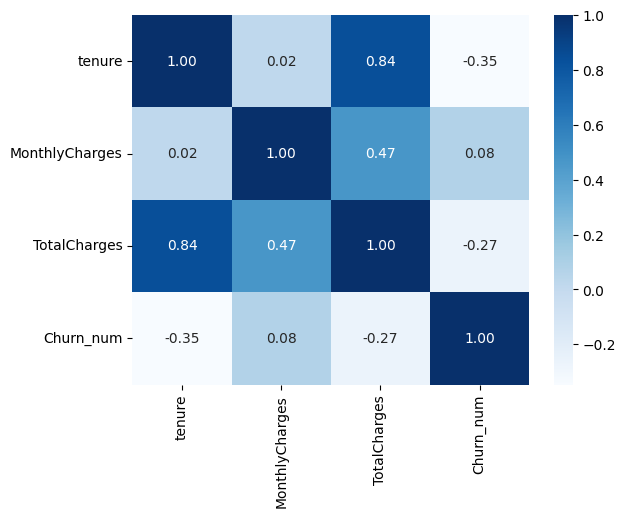

In [28]:
ax13 = sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f')
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`annot=True` 가 숫자 표시, `fmt='.2f'` 는 소수 둘째 자리

</details>

In [29]:
check.p02_q13()

✅ [P02 문제 13] heatmap (annot) — 정답!


### ✏️ 문제 14. 그래프 해석
`tenure` 와 상관계수가 가장 높은 **다른** 컬럼의 이름을 **`answer14`** 에 저장하세요.

In [30]:
answer14 = 'TotalCharges'

<details><summary>💡 힌트 (막히면 클릭)</summary>

heatmap 에서 tenure 행을 따라가 보세요 (자기 자신 1.00 은 제외).

코드: `corr['tenure'].drop('tenure').idxmax()`

</details>

In [31]:
check.p02_q14()

✅ [P02 문제 14] 그래프 해석: tenure 와 가장 상관 높은 컬럼 — 정답!
   TotalCharges: 가입기간이 길수록 누적요금도 커지니 당연하죠.


## 7. matplotlib 으로 꾸미기 (시험 14번: 학습 곡선 그래프 유형)
```python
plt.title('제목')    plt.xlabel('x축 이름')    plt.ylabel('y축 이름')    plt.legend(['선1', '선2'])    plt.show()
```

### ✏️ 문제 15. 제목과 축 이름
월 요금 히스토그램에 제목 **`'Monthly Charges'`**, x축 **`'MonthlyCharges'`**, y축 **`'Count'`** 를 다세요.

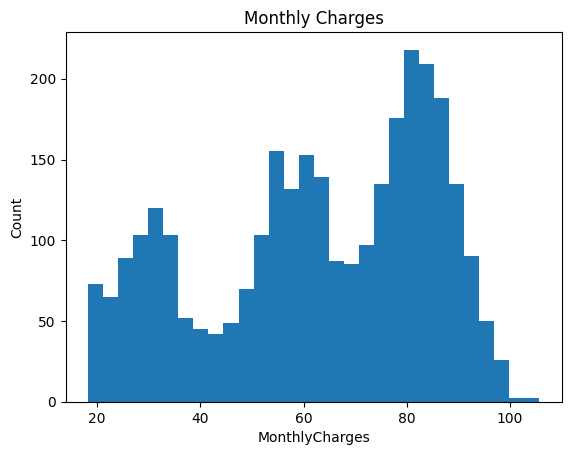

In [32]:
plt.hist(df_clean['MonthlyCharges'], bins=30)
plt.title('Monthly Charges')
plt.xlabel('MonthlyCharges')
plt.ylabel('Count')
ax15 = plt.gca()      # 지금 그리고 있는 그래프(Axes) 가져오기 → 채점용
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`plt.title`, `plt.xlabel`, `plt.ylabel`

</details>

In [33]:
check.p02_q15()

✅ [P02 문제 15] matplotlib 제목/축 이름 — 정답!


### ✏️ 문제 16. subplots 로 나란히
그래프 2개를 가로로 나란히 그리세요. 왼쪽 `gender`, 오른쪽 `Partner` 의 countplot.

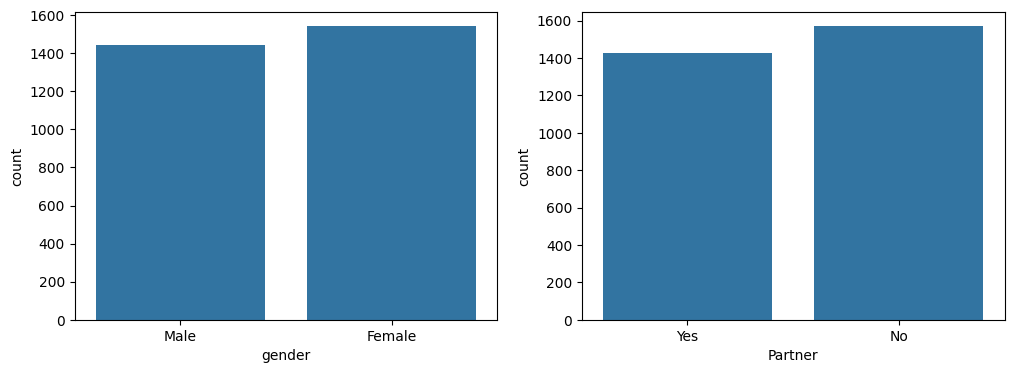

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))     # 1행 2열
sns.countplot(data=df_clean, x='gender', ax=axes[0])
sns.countplot(data=df_clean, x='Partner', ax=axes[1])
plt.show()

<details><summary>💡 힌트 (막히면 클릭)</summary>

`plt.subplots(행, 열)` → axes[0] 이 왼쪽, axes[1] 이 오른쪽. seaborn 함수에 `ax=` 로 위치를 지정해요.

</details>

In [35]:
check.p02_q16()

✅ [P02 문제 16] subplots 로 나란히 그리기 — 정답!


## 🏁 마무리

In [36]:
check.progress()

P02: 16/16 정답 ■■■■■■■■■■■■■■■■


| 질문 | 그래프 | 코드 |
|---|---|---|
| 범주별 개수는? | countplot | `sns.countplot(data=df, x='a', hue='b')` |
| 숫자 분포는? | histplot / kdeplot | `sns.histplot(data=df, x='a', bins=30)` |
| 이상치가 있나? | boxplot / jointplot | `sns.boxplot(data=df, y='a')` |
| 두 숫자의 관계는? | scatterplot / jointplot | `sns.jointplot(data=df, x='a', y='b')` |
| 그룹별 평균은? | barplot | `sns.barplot(data=df, x='그룹', y='숫자')` |
| 무엇끼리 관련 있나? | heatmap | `sns.heatmap(df.corr(numeric_only=True), annot=True)` |

다음: **`03_전처리_실습.ipynb`**